Shape of X: (4424, 36)
Shape of y: (4424, 1)

Metadata:
 {'uci_id': 697, 'name': "Predict Students' Dropout and Academic Success", 'repository_url': 'https://archive.ics.uci.edu/dataset/697/predict+students+dropout+and+academic+success', 'data_url': 'https://archive.ics.uci.edu/static/public/697/data.csv', 'abstract': "A dataset created from a higher education institution (acquired from several disjoint databases) related to students enrolled in different undergraduate degrees, such as agronomy, design, education, nursing, journalism, management, social service, and technologies.\nThe dataset includes information known at the time of student enrollment (academic path, demographics, and social-economic factors) and the students' academic performance at the end of the first and second semesters. \nThe data is used to build classification models to predict students' dropout and academic sucess. The problem is formulated as a three category classification task, in which there is a strong i

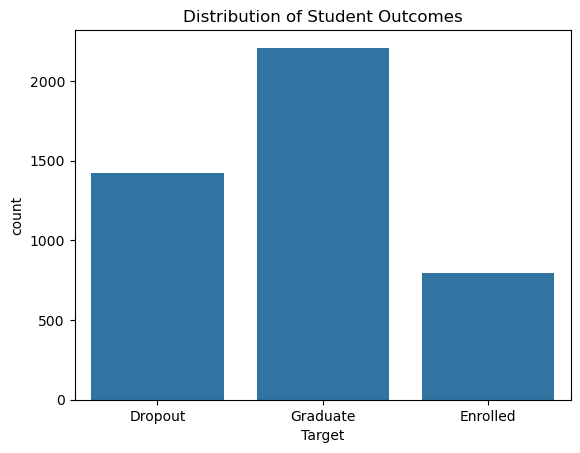

In [ ]:
from ucimlrepo import fetch_ucirepo
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

data = fetch_ucirepo(id=697)

X = data.data.features
y = data.data.targets

print("Shape of X:", X.shape)
print("Shape of y:", y.shape)
print("\nMetadata:\n", data.metadata)
print("\nVariables:\n", data.variables.head())

print(X.head())
print(y.head())

df = pd.concat([X, y], axis=1)
print(df.info())

sns.countplot(x='Target', data=df)
plt.title('Distribution of Student Outcomes')
plt.show()


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Shape of X_train_scaled:", X_train_scaled.shape)
print("Shape of y_train:", y_train.shape)


Shape of X_train_scaled: (3539, 36)
Shape of y_train: (3539,)


Train a random forest

In [14]:
# Train a random forest
model = RandomForestClassifier(random_state=42)
model.fit(X_train_scaled, y_train)

# Evaluate
y_pred = model.predict(X_test_scaled)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred))


Accuracy: 0.7615819209039548

Classification Report:
               precision    recall  f1-score   support

           0       0.85      0.77      0.81       316
           1       0.49      0.30      0.38       151
           2       0.76      0.92      0.83       418

    accuracy                           0.76       885
   macro avg       0.70      0.67      0.67       885
weighted avg       0.75      0.76      0.75       885


Confusion Matrix:
 [[244  23  49]
 [ 34  46  71]
 [  9  25 384]]


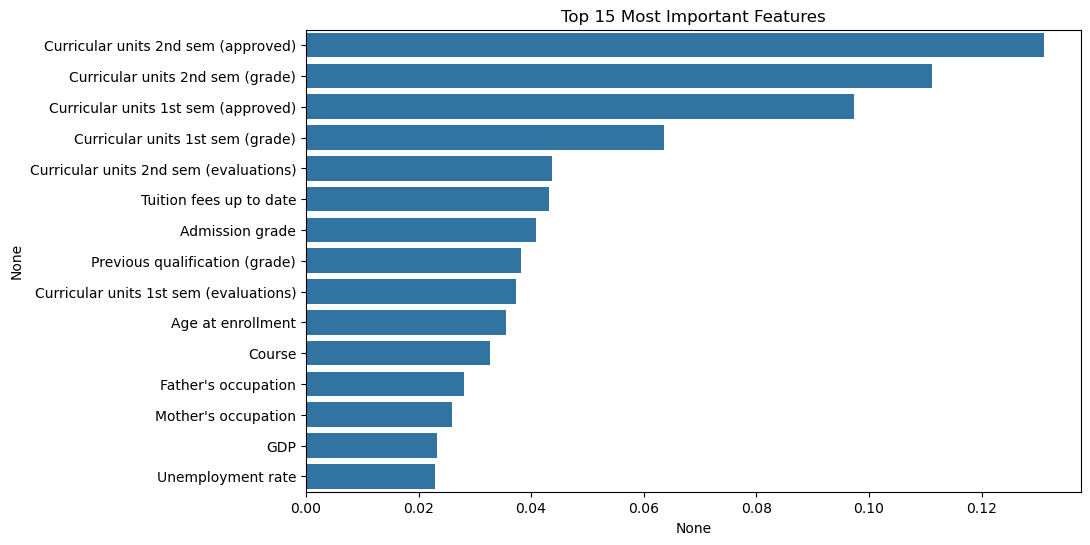

In [15]:
import numpy as np

feature_importance = pd.Series(model.feature_importances_, index=X.columns).sort_values(ascending=False)
plt.figure(figsize=(10,6))
sns.barplot(x=feature_importance[:15], y=feature_importance.index[:15])
plt.title("Top 15 Most Important Features")
plt.show()


Train a Logistic Regression model

In [18]:
from sklearn.linear_model import LogisticRegression
#Train a Logistic Regression model
model = LogisticRegression(max_iter=1000, random_state=42)
model.fit(X_train_scaled, y_train)

# Evaluate model
y_pred = model.predict(X_test_scaled)

print(" Accuracy:", accuracy_score(y_test, y_pred))
print("\n Classification Report:\n", classification_report(y_test, y_pred))
print("\n Confusion Matrix:\n", confusion_matrix(y_test, y_pred))



 Accuracy: 0.752542372881356

 Classification Report:
               precision    recall  f1-score   support

           0       0.83      0.77      0.80       316
           1       0.45      0.28      0.34       151
           2       0.76      0.91      0.83       418

    accuracy                           0.75       885
   macro avg       0.68      0.65      0.66       885
weighted avg       0.73      0.75      0.74       885


 Confusion Matrix:
 [[244  27  45]
 [ 35  42  74]
 [ 14  24 380]]


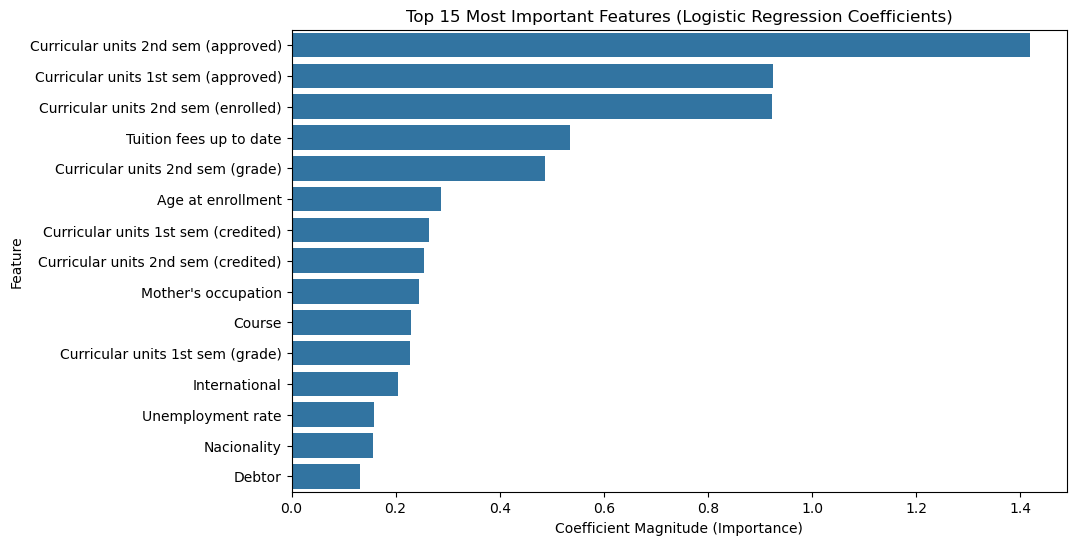

In [20]:
importance = pd.Series(np.abs(model.coef_[0]), index=X.columns).sort_values(ascending=False)

# Plot top 15 features
plt.figure(figsize=(10,6))
sns.barplot(x=importance[:15], y=importance.index[:15])
plt.title("Top 15 Most Important Features (Logistic Regression Coefficients)")
plt.xlabel("Coefficient Magnitude (Importance)")
plt.ylabel("Feature")
plt.show()


Train a Neural Network

In [ ]:
from tensorflow import random
from keras.models import Sequential
from keras.layers import Dense
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import train_test_split
seed = 4337
np.random.seed(seed)
random.set_seed(seed)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

encoder = OneHotEncoder(sparse_output=False)
y_onehot = encoder.fit_transform(y)

X_train, X_test, y_train, y_test = train_test_split(X_scaled, y_onehot, test_size=0.2, random_state=seed)

print("Shape of X_train:", X_train.shape)
print("Shape of y_train:", y_train.shape)
print("Shape of X_test:", X_test.shape)
print("Shape of y_test:", y_test.shape)

Shape of X_train: (3539, 36)
Shape of y_train: (3539, 3)
Shape of X_test: (885, 36)
Shape of y_test: (885, 3)


In [33]:
n_features = X_train.shape[1]
model_3 = Sequential()
model_3.add(Dense(16, activation='relu', input_shape=(n_features,)))
model_3.add(Dense(16, activation='relu'))
model_3.add(Dense(3, activation='softmax'))
model_3.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
model_3.summary()


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_6 (Dense)                 │ (None, 16)             │           592 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 16)             │           272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 3)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 915 (3.57 KB)

 Trainable params: 915 (3.57 KB)

 Non-trainable params: 0 (0.00 B)

In [34]:
epochs = 50
batch_size = 5
history_3 = model_3.fit(
    X_train, y_train,
    epochs=epochs,
    batch_size=batch_size,
    validation_split=0.1,
    verbose=1
)
loss_3, accuracy_3 = model_3.evaluate(X_test, y_test, verbose=0)
print(f"Model 3 (Wider)    - Test Accuracy: {accuracy_3:.4f}")


Epoch 1/50
637/637 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.6794 - loss: 0.7644 - val_accuracy: 0.7316 - val_loss: 0.6443
Epoch 2/50
637/637 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7444 - loss: 0.6189 - val_accuracy: 0.7373 - val_loss: 0.6041
Epoch 3/50
637/637 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7538 - loss: 0.5837 - val_accuracy: 0.7345 - val_loss: 0.5958
Epoch 4/50
637/637 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7614 - loss: 0.5670 - val_accuracy: 0.7401 - val_loss: 0.5946
Epoch 5/50
637/637 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7639 - loss: 0.5559 - val_accuracy: 0.7514 - val_loss: 0.5896
Epoch 6/50
637/637 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7677 - loss: 0.5469 - val_accuracy: 0.7514 - val_loss: 0.5856
Epoch 7/50
637/637 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7692 - loss: 0.5402 - val_accuracy: 0.7514 - val_loss: 0.5842
Epoch 8/50
637/637 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7755 - loss: 0.5335 - val_accuracy: 0.

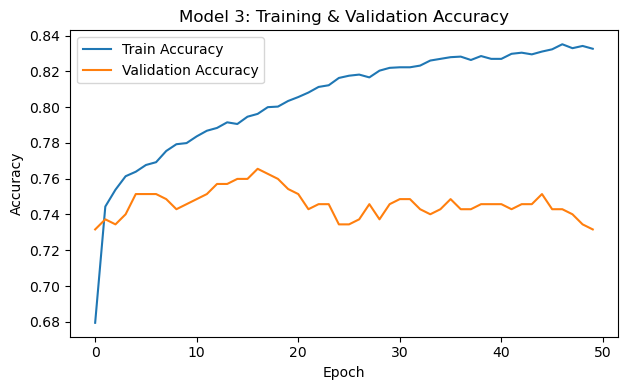

28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
Confusion Matrix:
 [[207  46  33]
 [ 35  68  59]
 [ 13  41 383]]

Classification Report:
               precision    recall  f1-score   support

           0       0.81      0.72      0.77       286
           1       0.44      0.42      0.43       162
           2       0.81      0.88      0.84       437

    accuracy                           0.74       885
   macro avg       0.69      0.67      0.68       885
weighted avg       0.74      0.74      0.74       885



In [35]:
history = history_3
plt.figure(figsize=(12, 4))

# Plot Training & Validation Accuracy
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model 3: Training & Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

# Similarly Plot Training & Validation Loss


plt.tight_layout()
plt.show()


# --- B. Confusion Matrix & Classification Report ---
y_pred_probs = model_3.predict(X_test)
y_pred = np.argmax(y_pred_probs, axis=1)  
y_true = np.argmax(y_test, axis=1)    

cm = confusion_matrix(y_true, y_pred)
print("Confusion Matrix:\n", cm)

print("\nClassification Report:\n", classification_report(y_true, y_pred, target_names=data.target_names))